# 05 — Consolidação Histórica da Década de Ouro (ENEM 2014–2023)

**Projeto de TCC — MBA em Ciência de Dados & MLOps**  
**Autor:** Saulo Santos  

---

## 🎯 Papel Arquitetural deste Notebook

Este notebook executa a **Engenharia de Dados e Consolidação Longitudinal** da **Etapa 1** do projeto. Ele recebe os contratos validados nos Notebooks **03** (seleção do alvo `TARGET_M4` e das 6 features de elite) e **04** (harmonização semântica via SBERT de 2009 a 2025) e constrói a tabela unificada que alimentará o treinamento do modelo no **Notebook 06**:

```text
[01_investigacao] ──> [02_eda (2023)] ──> [03_features (2023)] ──> [04_nlp_sbert (2009–2025)]
                                                                               │
                                                                               ▼
                  enem.pkl <── [06_treinamento_modelo] <── [05_consolidacao_historica (2014–2023)]
```

### Escopo Estrito de Dados (Parcimônia + Eficiência de Memória RAM)
Os arquivos CSV brutos de 2014 a 2023 somam **~27,3 GB** em disco porque carregam mais de 70 colunas administrativas, textos e gabaritos. Como o nosso modelo utiliza apenas **6 features preditoras + 1 alvo + 1 coluna de ano**, filtramos e compactamos cada registro na origem para ocupar apenas **15 bytes em memória RAM**:

| Coluna | Papel no Projeto | Tipo Otimizado | Custo por Linha |
| :--- | :--- | :---: | :---: |
| `NU_ANO` | Partição temporal (`2014` a `2023`) — *não entra como feature* | `int16` | 2 bytes |
| `RENDA_PER_CAPITA` | Feature #1 — Renda familiar em Salários Mínimos por morador | `float32` | 4 bytes |
| `Q024` | Feature #2 — Posse de computador no domicílio (`0` a `3`) | `int8` | 1 byte |
| `TP_ANO_CONCLUIU` | Feature #3 — Anos desde a conclusão do Ensino Médio (`0` a `9`) | `int8` | 1 byte |
| `TP_LINGUA` | Feature #4 — Língua estrangeira (`0` = Inglês, `1` = Espanhol) | `int8` | 1 byte |
| `TP_SEXO` | Feature #5 — Sexo (`0` = Feminino, `1` = Masculino) | `int8` | 1 byte |
| `Q002` | Feature #6 — Escolaridade materna (`0` a `7`) | `int8` | 1 byte |
| `TARGET_M4` | Alvo Oficial (`y`) — Média das 4 provas objetivas da TRI | `float32` | 4 bytes |
| **TOTAL** | **Censo Completo da Década (~37 milhões de presentes)** | **Compactado** | **15 bytes (~560 MB)** |

> **Documentação Complementar:** Consulte o arquivo [`passo-a-passo-05.md`](../passo-a-passo-05.md) na raiz do repositório para uma explicação detalhada dos fundamentos estatísticos, escolhas de engenharia e guia de validação deste notebook.

---
## 1. Configuração do Ambiente, Caminhos e Telemetria de Memória RAM

### O que esta célula faz?
Esta primeira célula prepara toda a infraestrutura básica do notebook dividida em **4 blocos simples**:
* **Bloco 1.1 (Importações):** Carrega as bibliotecas padrão do Python (`json`, `hashlib`, `pathlib`, `gc`, `time`) e a pilha científica (`numpy`, `pandas`, `pyarrow`, `psutil`, `matplotlib`, `seaborn`).
* **Bloco 1.2 (Reprodutibilidade e Visualização):** Fixa a semente aleatória (`SEED = 42`) e padroniza o tema visual dos gráficos para a dissertação.
* **Bloco 1.3 (Resolução Resiliente de Diretórios):** Descobre automaticamente a pasta raiz do projeto (`enem/`), independentemente de onde o Jupyter tenha sido iniciado, e define os caminhos dos arquivos de entrada, *checkpoints* intermediários e artefatos finais.
* **Bloco 1.4 (Monitor de Memória RAM):** Cria a função `obter_telemetria_ram()`, que consulta em tempo real quanta memória RAM o processo Python está usando e quanta memória permanece livre na máquina.

In [3]:
# ==============================================================================
# SEÇÃO 1: CONFIGURAÇÃO DO AMBIENTE, CAMINHOS E TELEMETRIA DE MEMÓRIA RAM
# ==============================================================================

# ── Bloco 1.1: Importação das bibliotecas necessárias ─────────────────────────
from datetime import datetime, timezone
import gc
import hashlib
import json
import os
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import seaborn as sns

# ── Bloco 1.2: Reprodutibilidade determinística e padrão visual dos gráficos ──
# Fixamos SEED = 42 para garantir que qualquer operação estocástica futura seja
# 100% reprodutível, mantendo o mesmo padrão adotado nos Notebooks 01 a 04.
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"


# ── Bloco 1.3: Localização dinâmica da raiz do repositório e caminhos ─────────
def localizar_raiz_projeto() -> Path:
    """
    Percorre o diretório atual e seus diretórios-pai até encontrar a raiz do
    projeto (identificada pela presença conjunta de 'data/processed' e 'notebooks').
    Isso evita erros de caminho relativo ('FileNotFoundError') ao rodar células.
    """
    atual = Path.cwd().resolve()
    for candidato in [atual] + list(atual.parents):
        if (candidato / "data" / "processed").exists() and (candidato / "notebooks").exists():
            return candidato
    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto contendo 'data/processed' e 'notebooks'."
    )


PROJECT_ROOT = localizar_raiz_projeto()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Pasta dedicada aos checkpoints anuais enxutos (permite retomar de onde parou)
CHECKPOINT_DIR = PROCESSED_DIR / "safras_consolidacao"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Contratos de entrada (gerado no Notebook 04) e saídas oficiais (para o Notebook 06)
CAMINHO_SCHEMA_MAPPING = PROCESSED_DIR / "schema_mapping_historico.json"
CAMINHO_PARQUET_FINAL = PROCESSED_DIR / "enem_2014_2023_consolidado.parquet"
CAMINHO_CONTRATO_FINAL = PROCESSED_DIR / "contrato_consolidacao_2014_2023.json"


# ── Bloco 1.4: Função utilitária de telemetria de memória RAM ─────────────────
def obter_telemetria_ram() -> dict:
    """
    Mede o consumo real de memória física (RSS) deste kernel Python em MB e a
    memória RAM disponível no sistema operacional em GB.
    """
    proc = psutil.Process(os.getpid())
    vm = psutil.virtual_memory()
    return {
        "processo_rss_mb": round(proc.memory_info().rss / (1024 ** 2), 2),
        "sistema_disponivel_gb": round(vm.available / (1024 ** 3), 2),
        "sistema_total_gb": round(vm.total / (1024 ** 3), 2),
        "sistema_uso_pct": round(vm.percent, 1),
    }


ram_inicial = obter_telemetria_ram()

print("=" * 88)
print("AMBIENTE DE CONSOLIDAÇÃO HISTÓRICA INICIALIZADO COM SUCESSO")
print("=" * 88)
print(f"• Raiz do Projeto          : {PROJECT_ROOT}")
print(f"• Diretório de Dados Brutos: {RAW_DIR}")
print(f"• Diretório de Checkpoints : {CHECKPOINT_DIR}")
print(f"• Versões de Runtime       : pandas={pd.__version__} | numpy={np.__version__} | pyarrow={pa.__version__}")
print(
    f"• Telemetria Inicial de RAM: Processo={ram_inicial['processo_rss_mb']:.1f} MB | "
    f"Livre no Host={ram_inicial['sistema_disponivel_gb']:.2f} GB / {ram_inicial['sistema_total_gb']:.2f} GB"
)

AMBIENTE DE CONSOLIDAÇÃO HISTÓRICA INICIALIZADO COM SUCESSO
• Raiz do Projeto          : /home/saulo/mba/tcc/enem
• Diretório de Dados Brutos: /home/saulo/mba/tcc/enem/data/raw
• Diretório de Checkpoints : /home/saulo/mba/tcc/enem/data/processed/safras_consolidacao
• Versões de Runtime       : pandas=3.0.5 | numpy=2.5.3 | pyarrow=25.0.1
• Telemetria Inicial de RAM: Processo=214.8 MB | Livre no Host=6.30 GB / 7.70 GB


---
## 2. Carregamento e Validação do Contrato Semântico (`schema_mapping_historico.json`)

### O que esta célula faz?
Antes de abrir arquivos de vários gigabytes, validamos formalmente o contrato de governança produzido pelo **Notebook 04** em **4 blocos**:
* **Bloco 2.1 (Leitura do Contrato):** Carrega o JSON `schema_mapping_historico.json` e extrai os metadados de classificação das 17 edições varridas pelo SBERT (`2009` a `2025`).
* **Bloco 2.2 (Filtro Automático de Governança):** Seleciona exclusivamente os anos marcados como `"APROVADA_PARA_BASELINE"`, confirmando programaticamente a janela `2014` a `2023` (e impedindo a entrada acidental de `2009–2013`, `2024` ou `2025`).
* **Bloco 2.3 (Localizador Seguro de CSV):** Cria a função `localizar_csv_microdados(ano)` que encontra o arquivo monolítico `MICRODADOS_ENEM_{ano}.csv` de cada edição e ignora tabelas auxiliares (como `ITENS_PROVA`).
* **Bloco 2.4 (Auditoria de Cabeçalhos Físicos e Injetividade):** Abre apenas a linha `0` (cabeçalho, sem carregar dados) de cada um dos 10 CSVs para confirmar que as **15 colunas mapeadas pelo SBERT** e a **coluna administrativa de controle (`NU_INSCRICAO`, lida diretamente do CSV)** existem fisicamente no arquivo, sem colisão de nomes.

In [4]:
# ==============================================================================
# SEÇÃO 2: VALIDAÇÃO DO CONTRATO SEMÂNTICO E AUDITORIA DE CABEÇALHOS CSV
# ==============================================================================

# ── Bloco 2.1: Leitura defensiva do contrato JSON gerado pelo Notebook 04 ─────
if not CAMINHO_SCHEMA_MAPPING.exists():
    raise FileNotFoundError(
        f"Contrato semântico não encontrado em {CAMINHO_SCHEMA_MAPPING}. "
        "Execute o Notebook 04 antes de prosseguir."
    )

with open(CAMINHO_SCHEMA_MAPPING, "r", encoding="utf-8") as f:
    contrato_sbert = json.load(f)

metadata_sbert = contrato_sbert.get("_metadata", {})
classificacao_edicoes = metadata_sbert.get("classificacao_edicoes", {})

# ── Bloco 2.2: Seleção estrita das edições homologadas para o Baseline ────────
# Apenas edições com status 'APROVADA_PARA_BASELINE' têm permissão para entrar
# no dataset de treinamento (2014 a 2023 — Década de Ouro).
ANOS_HOMOLOGADOS = sorted(
    int(ano)
    for ano, info in classificacao_edicoes.items()
    if info.get("status_governanca") == "APROVADA_PARA_BASELINE"
)

assert ANOS_HOMOLOGADOS == list(range(2014, 2024)), (
    f"Inconsistência de governança! Esperado 2014..2023, obtido: {ANOS_HOMOLOGADOS}"
)

# As exatas 15 variáveis canônicas do CONTRATO_CANONICO homologadas no Notebook 04:
# 7 insumos de features (Q006, Q005, Q024, Q002, TP_ANO_CONCLUIU, TP_LINGUA, TP_SEXO)
# + 4 flags de presença + 4 notas objetivas da TRI.
COLUNAS_CANONICAS_15 = [
    "Q006",
    "Q005",
    "Q024",
    "Q002",
    "TP_ANO_CONCLUIU",
    "TP_LINGUA",
    "TP_SEXO",
    "TP_PRESENCA_CN",
    "TP_PRESENCA_CH",
    "TP_PRESENCA_LC",
    "TP_PRESENCA_MT",
    "NU_NOTA_CN",
    "NU_NOTA_CH",
    "NU_NOTA_LC",
    "NU_NOTA_MT",
]

# Coluna administrativa extra lida diretamente do cabeçalho físico do CSV
# (fora do schema_mapping_historico.json, seguindo o padrão do scripts/etl_parquet.py)
# exclusivamente para auditar unicidade anual de candidatos antes de descartá-la.
COLUNA_CONTROLE_CSV = "NU_INSCRICAO"


# ── Bloco 2.3: Descoberta automática do arquivo CSV principal de cada safra ───
def localizar_csv_microdados(ano: int) -> Path:
    """
    Busca recursivamente dentro de data/raw/enem_{ano} o arquivo CSV monolítico
    dos participantes (MICRODADOS_ENEM_{ano}.csv), ignorando arquivos acessórios
    de itens de prova, questionários avulsos ou hábitos de estudo.
    """
    pasta_ano = RAW_DIR / f"enem_{ano}"
    candidatos = sorted(pasta_ano.rglob("*.csv"))
    termos_ignorar = ("ITENS", "HAB_ESTUDO", "PROVA", "RESULTADOS", "QUESTIONARIO")
    validos = [
        p for p in candidatos
        if "MICRODADOS" in p.name.upper()
        and not any(termo in p.name.upper() for termo in termos_ignorar)
    ]
    if not validos:
        raise FileNotFoundError(f"Nenhum CSV principal de microdados encontrado em {pasta_ano}")
    return validos[0]


# ── Bloco 2.4: Verificação física dos cabeçalhos CSV e da injetividade 1:1 ────
ARQUIVOS_CSV_POR_ANO = {}
resumo_governanca = []

for ano in ANOS_HOMOLOGADOS:
    ano_str = str(ano)
    mapa_ano = contrato_sbert[ano_str]

    # Garante que todas as 15 colunas canônicas estão mapeadas e sem duplicidade (1:1)
    faltantes_contrato = [c for c in COLUNAS_CANONICAS_15 if c not in mapa_ano]
    assert not faltantes_contrato, f"Ano {ano}: colunas ausentes no contrato: {faltantes_contrato}"
    assert len(mapa_ano) == len(COLUNAS_CANONICAS_15) and len(set(mapa_ano.values())) == len(mapa_ano), (
        f"Ano {ano}: cardinalidade ou colisão de schema detectada no mapeamento {mapa_ano}!"
    )

    caminho_csv = localizar_csv_microdados(ano)
    ARQUIVOS_CSV_POR_ANO[ano] = caminho_csv

    # nrows=0 lê apenas a primeira linha (cabeçalho) instantaneamente e com custo zero de RAM
    header_df = pd.read_csv(caminho_csv, sep=";", encoding="latin-1", nrows=0)
    colunas_fisicas = set(header_df.columns)
    faltantes_csv = [
        mapa_ano[c] for c in COLUNAS_CANONICAS_15 if mapa_ano[c] not in colunas_fisicas
    ]
    assert not faltantes_csv, (
        f"Ano {ano}: colunas mapeadas ausentes fisicamente em {caminho_csv.name}: {faltantes_csv}"
    )
    assert COLUNA_CONTROLE_CSV in colunas_fisicas, (
        f"Ano {ano}: coluna administrativa '{COLUNA_CONTROLE_CSV}' ausente em {caminho_csv.name}!"
    )

    # Identifica quais colunas sofreram mudança de nome naquela edição (ex.: 2014)
    drifts_nominais = [
        f"{raw_col} -> {can_col}"
        for can_col, raw_col in mapa_ano.items()
        if can_col != raw_col
    ]

    resumo_governanca.append({
        "Ano": ano,
        "Status Governança": classificacao_edicoes[ano_str]["status_governanca"],
        "Arquivo CSV Físico": caminho_csv.name,
        "Tamanho CSV (GB)": round(caminho_csv.stat().st_size / (1024 ** 3), 2),
        "Colunas Físicas": "15/15 + ID OK",
        "Traduções Semânticas (Drift)": (
            ", ".join(drifts_nominais) if drifts_nominais else "Nomenclatura Idêntica (2023)"
        ),
    })

df_governanca_anos = pd.DataFrame(resumo_governanca)
print("=" * 95)
print(
    f"CONTRATO SEMÂNTICO VALIDADO (v{metadata_sbert.get('versao_contrato', 'N/A')}) — "
    f"{len(ANOS_HOMOLOGADOS)} EDIÇÕES HOMOLOGADAS | VOLUME BRUTO TOTAL: "
    f"{df_governanca_anos['Tamanho CSV (GB)'].sum():.2f} GB"
)
print("=" * 95)
display(df_governanca_anos)

CONTRATO SEMÂNTICO VALIDADO (v3.5 (Auditoria física amostral, integridade referencial e governança por testes)) — 10 EDIÇÕES HOMOLOGADAS | VOLUME BRUTO TOTAL: 25.45 GB


,Ano,Status Governança,Arquivo CSV Físico,Tamanho CSV (GB),Colunas Físicas,Traduções Semânticas (Drift)
0,2014,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2014.csv,4.79,15/15 + ID OK,"Q003 -> Q006, Q004 -> Q005, Q010 -> Q024"
1,2015,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2015.csv,3.78,15/15 + ID OK,Nomenclatura Idêntica (2023)
2,2016,APROVADA_PARA_BASELINE,microdados_enem_2016.csv,4.04,15/15 + ID OK,Nomenclatura Idêntica (2023)
3,2017,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2017.csv,2.81,15/15 + ID OK,Nomenclatura Idêntica (2023)
4,2018,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2018.csv,1.38,15/15 + ID OK,Nomenclatura Idêntica (2023)
5,2019,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2019.csv,2.24,15/15 + ID OK,Nomenclatura Idêntica (2023)
6,2020,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2020.csv,1.89,15/15 + ID OK,Nomenclatura Idêntica (2023)
7,2021,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2021.csv,1.40,15/15 + ID OK,Nomenclatura Idêntica (2023)
8,2022,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2022.csv,1.46,15/15 + ID OK,Nomenclatura Idêntica (2023)
9,2023,APROVADA_PARA_BASELINE,MICRODADOS_ENEM_2023.csv,1.66,15/15 + ID OK,Nomenclatura Idêntica (2023)


---
## 3. Regras de Harmonização Longitudinal (*Anti-Value Drift*) e *Downcasting*

### Por que esta célula é o coração metodológico do Notebook 05?
Renomear colunas resolve o *Schema Drift* (nomes diferentes), mas não resolve o ***Value Drift*** (mudanças no significado interno das letras/códigos ou inflação monetária ao longo de 10 anos). Nesta célula definimos **6 blocos de regras explícitas e auditáveis**:

* **Bloco 3.1 (Contrato Ordenado de Colunas):** Fixa a ordem imutável das 6 features preditoras (`FEATURES_ELITE`), do alvo (`TARGET_M4`) e do ano (`NU_ANO`).
* **Bloco 3.2 (Deflação em Salários Mínimos — `RENDA_PER_CAPITA`):** Em 2014 o Salário Mínimo era `R$ 724,00`; em 2023 era `R$ 1.320,00` (+82,3% nominais). Como o INEP manteve nos 10 anos as mesmas **17 faixas (`A` a `Q`) em múltiplos de Salário Mínimo**, convertemos cada letra para seu ponto médio em **Salários Mínimos** (`0,00` a `22,50` SM) e dividimos pelo número de moradores (`1` a `20`). Assim, `1,0 SM per capita` em 2014 tem exatamente o mesmo significado socioeconômico que `1,0 SM per capita` em 2023.
* **Bloco 3.3 (Harmonização de Computador — `Q024`):** Corrige a inversão documental de 2014, onde `Q010` codificava **`D = Não tenho` (`0`)** e `A = 1 computador` (`1`), alinhando-a ao padrão 2015–2023 (`0 = Nenhum`, `1 = Um`, `2 = Dois`, `3 = Três ou mais`).
* **Bloco 3.4 (Harmonização da Escolaridade Materna — `Q002`):** Alinha as 9 categorias de 2014 (`A` a `I`, em que `E` e `F` dividiam Ensino Médio completo e Superior incompleto, `H` era Pós-graduação e `I` era Não sei) com as 8 categorias de 2015–2023 (`0` a `7`).
* **Bloco 3.5 ( Variáveis Binárias e Teto Estacionário de Conclusão):** Define `TP_SEXO` (`F=0, M=1`), `TP_LINGUA` (`0=Inglês, 1=Espanhol`) e fixa `TETO_ANOS_CONCLUSAO = 9` (`9+ anos desde a conclusão`), evitando que códigos altos exclusivos de anos recentes (ex.: `17` em 2023) vazem o ano da prova.
* **Bloco 3.6 (Tabela de *Downcasting*):** Demonstra matematicamente a economia de `64 bytes/linha` para **`15 bytes/linha`** (`-76,6%` de memória RAM).

In [5]:
# ==============================================================================
# SEÇÃO 3: DICIONÁRIOS AUDITÁVEIS DE HARMONIZAÇÃO E ORÇAMENTO DE MEMÓRIA
# ==============================================================================

# ── Bloco 3.1: Ordem canônica das colunas (compartilhada com Notebook 06 e API) ─
FEATURES_ELITE = [
    "RENDA_PER_CAPITA",
    "Q024",
    "TP_ANO_CONCLUIU",
    "TP_LINGUA",
    "TP_SEXO",
    "Q002",
]
ALVO_OFICIAL = "TARGET_M4"
COLUNA_PARTICAO_TEMPORAL = "NU_ANO"
COLUNAS_DATASET_CONSOLIDADO = [COLUNA_PARTICAO_TEMPORAL] + FEATURES_ELITE + [ALVO_OFICIAL]

# Colunas transitórias lidas do CSV apenas para filtro de elegibilidade e cálculo do alvo
COLS_PRESENCA = ["TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT"]
COLS_NOTAS_TRI = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT"]

# ── Bloco 3.2: Deflação estrutural da renda familiar em Salários Mínimos (SM) ──
# Cada letra de A a Q representa exatamente a mesma faixa em Salários Mínimos
# tanto em 2014 (Q003) quanto em 2015–2023 (Q006). Usamos o ponto médio da faixa.
MAPA_Q006_SALARIOS_MINIMOS = {
    "A": 0.00,   # Nenhuma renda
    "B": 0.50,   # Até 1 SM            -> ponto médio (0,0 + 1,0) / 2 = 0,50 SM
    "C": 1.25,   # De 1 a 1,5 SM       -> ponto médio (1,0 + 1,5) / 2 = 1,25 SM
    "D": 1.75,   # De 1,5 a 2 SM       -> ponto médio (1,5 + 2,0) / 2 = 1,75 SM
    "E": 2.25,   # De 2 a 2,5 SM       -> ponto médio (2,0 + 2,5) / 2 = 2,25 SM
    "F": 2.75,   # De 2,5 a 3 SM       -> ponto médio (2,5 + 3,0) / 2 = 2,75 SM
    "G": 3.50,   # De 3 a 4 SM         -> ponto médio (3,0 + 4,0) / 2 = 3,50 SM
    "H": 4.50,   # De 4 a 5 SM         -> ponto médio (4,0 + 5,0) / 2 = 4,50 SM
    "I": 5.50,   # De 5 a 6 SM         -> ponto médio (5,0 + 6,0) / 2 = 5,50 SM
    "J": 6.50,   # De 6 a 7 SM         -> ponto médio (6,0 + 7,0) / 2 = 6,50 SM
    "K": 7.50,   # De 7 a 8 SM         -> ponto médio (7,0 + 8,0) / 2 = 7,50 SM
    "L": 8.50,   # De 8 a 9 SM         -> ponto médio (8,0 + 9,0) / 2 = 8,50 SM
    "M": 9.50,   # De 9 a 10 SM        -> ponto médio (9,0 + 10,0) / 2 = 9,50 SM
    "N": 11.00,  # De 10 a 12 SM       -> ponto médio (10,0 + 12,0) / 2 = 11,00 SM
    "O": 13.50,  # De 12 a 15 SM       -> ponto médio (12,0 + 15,0) / 2 = 13,50 SM
    "P": 17.50,  # De 15 a 20 SM       -> ponto médio (15,0 + 20,0) / 2 = 17,50 SM
    "Q": 22.50,  # Acima de 20 SM      -> teto representativo padronizado (22,50 SM)
}

# ── Bloco 3.3: Harmonização de Q024 (Posse de Computador no Domicílio) ─────────
# Escala unificada: 0 = Nenhum | 1 = Um | 2 = Dois | 3 = Três ou mais computadores
# Atenção: em 2014 (Q010), 'D' significava 'Não tenho' e 'A' significava '1'!
MAPA_Q024_2014 = {"D": 0, "A": 1, "B": 2, "C": 3}
MAPA_Q024_2015_2023 = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 3}

# ── Bloco 3.4: Harmonização de Q002 (Escolaridade da Mãe ou Responsável) ───────
# Escala unificada: 0=Nunca estudou | 1=EF I inc. | 2=EF II inc. | 3=EM inc. |
#                   4=EM comp./Sup. inc. | 5=Superior comp. | 6=Pós-grad. | 7=Não sei
MAPA_Q002_2014 = {
    "A": 0, "B": 1, "C": 2, "D": 3,
    "E": 4, "F": 4,  # Em 2014 'E' (EM completo) e 'F' (Superior incompleto) equivalem ao 'E' de 2015–2023
    "G": 5,          # Ensino Superior completo
    "H": 6,          # Pós-graduação
    "I": 7,          # Não sei
}
MAPA_Q002_2015_2023 = {
    "A": 0, "B": 1, "C": 2, "D": 3,
    "E": 4, "F": 5, "G": 6, "H": 7,
}

# ── Bloco 3.5: Variáveis binárias invariantes e teto estacionário de conclusão ─
MAPA_TP_SEXO = {"F": 0, "M": 1}    # Idêntico ao OrdinalEncoder alfabético do Notebook 03
MAPA_TP_LINGUA = {"0": 0, "1": 1}  # 0 = Inglês | 1 = Espanhol
TETO_ANOS_CONCLUSAO = 9            # Escala estacionária {0..9} comum aos 10 anos

# ── Bloco 3.6: Dicionário de Downcasting e cálculo do orçamento de bytes ───────
TIPOS_COMPACTOS = {
    "NU_ANO": "int16",
    "RENDA_PER_CAPITA": "float32",
    "Q024": "int8",
    "TP_ANO_CONCLUIU": "int8",
    "TP_LINGUA": "int8",
    "TP_SEXO": "int8",
    "Q002": "int8",
    "TARGET_M4": "float32",
}

orcamento_bytes = [
    {
        "Coluna": col,
        "Papel": (
            "Partição Temporal" if col == "NU_ANO"
            else ("Alvo (y)" if col == ALVO_OFICIAL else "Feature Preditora (X)")
        ),
        "Tipo Padrão Pandas": "int64 / float64 (8 B)",
        "Tipo Otimizado": dtype,
        "Bytes Otimizado": np.dtype(dtype).itemsize,
    }
    for col, dtype in TIPOS_COMPACTOS.items()
]
df_orcamento = pd.DataFrame(orcamento_bytes)
bytes_por_linha = int(df_orcamento["Bytes Otimizado"].sum())
bytes_padrao = len(TIPOS_COMPACTOS) * 8

print("=" * 88)
print(
    f"ORÇAMENTO DE MEMÓRIA POR REGISTRO: {bytes_por_linha} BYTES/LINHA "
    f"(REDUÇÃO DE {(1 - bytes_por_linha / bytes_padrao) * 100:.1f}% FRENTE AOS {bytes_padrao} BYTES PADRÃO)"
)
print(
    f"• Projeção para 38 milhões de candidatos: ~{(38_000_000 * bytes_por_linha) / (1024 ** 2):.0f} MB em RAM"
)
print("=" * 88)
display(df_orcamento)

ORÇAMENTO DE MEMÓRIA POR REGISTRO: 15 BYTES/LINHA (REDUÇÃO DE 76.6% FRENTE AOS 64 BYTES PADRÃO)
• Projeção para 38 milhões de candidatos: ~544 MB em RAM


,Coluna,Papel,Tipo Padrão Pandas,Tipo Otimizado,Bytes Otimizado
0,NU_ANO,Partição Temporal,int64 / float64 (8 B),int16,2
1,RENDA_PER_CAPITA,Feature Preditora (X),int64 / float64 (8 B),float32,4
2,Q024,Feature Preditora (X),int64 / float64 (8 B),int8,1
3,TP_ANO_CONCLUIU,Feature Preditora (X),int64 / float64 (8 B),int8,1
4,TP_LINGUA,Feature Preditora (X),int64 / float64 (8 B),int8,1
5,TP_SEXO,Feature Preditora (X),int64 / float64 (8 B),int8,1
6,Q002,Feature Preditora (X),int64 / float64 (8 B),int8,1
7,TARGET_M4,Alvo (y),int64 / float64 (8 B),float32,4


---
## 4. Motor de Transformação por Bloco (*Chunk Engine*) e *Smoke Test*

### O que esta célula faz?
Antes de varrer dezenas de milhões de linhas, construímos e testamos o motor de transformação em **3 blocos bem definidos**:
* **Bloco 4.1 (`harmonizar_ano_concluiu`):** Função dedicada a converter `TP_ANO_CONCLUIU` para o intervalo estacionário `{0..9}` nos três formatos históricos do INEP (`2014` com anos civis literais `2004..2013`, `2015` com código deslocado em +1, e `2016–2023` no formato padrão).
* **Bloco 4.2 (`processar_chunk_enem`):** Pipeline puro de 6 passos aplicado sobre cada fatia de 500 mil linhas do CSV:
  1. Renomeia as colunas brutas para o padrão de 2023 usando o contrato semântico;
  2. Filtra apenas presentes nas 4 provas objetivas (`TP_PRESENCA_CN/CH/LC/MT == 1`);
  3. Valida notas em `[0, 1000]` e calcula `TARGET_M4`;
  4. Calcula `RENDA_PER_CAPITA` em Salários Mínimos e codifica as 5 features categóricas;
  5. Descarta questionários socioeconômicos deixados em branco (sem inventar renda artificial);
  6. Aplica o *downcasting* para **15 bytes/linha** e elimina imediatamente todas as colunas brutas de notas e presença (*Anti-Leakage*).
* **Bloco 4.3 (*Smoke Test Fail-Fast*):** Testa automaticamente a função em `5.000` linhas reais de `2014`, `2015` e `2023` para garantir zero erros antes do processamento completo.

In [6]:
# ==============================================================================
# SEÇÃO 4: FUNÇÃO MODULAR DE TRANSFORMAÇÃO DE CHUNKS E SMOKE TEST AUTOMATIZADO
# ==============================================================================


# ── Bloco 4.1: Harmonizador temporal da variável TP_ANO_CONCLUIU ───────────────
def harmonizar_ano_concluiu(serie_str: pd.Series, ano: int) -> pd.Series:
    """
    Traduz TP_ANO_CONCLUIU para anos relativos desde a conclusão do Ensino Médio
    na escala estacionária {0..9}:
      - 0     : Não informado / Concluinte no ano do exame
      - 1..8  : 1 a 8 anos decorridos desde a conclusão
      - 9     : 9 ou mais anos decorridos desde a conclusão
    Qualquer código inesperado fora do domínio retorna NaN para expurgo seguro.
    """
    s = serie_str.fillna("").astype(str).str.strip()
    resultado = pd.Series(np.nan, index=s.index, dtype="float64")

    if ano == 2014:
        # Em 2014, vazio/'0' representa não informado/concluinte; demais valores são anos civis (ex.: 2013 -> 1 ano)
        mask_zero = s.isin(["", "0"])
        resultado.loc[mask_zero] = 0.0
        num = pd.to_numeric(s.loc[~mask_zero], errors="coerce")
        validos = num.between(1900, 2014)
        idx_val = num.index[validos]
        resultado.loc[idx_val] = np.clip(2014 - num.loc[idx_val], 0, TETO_ANOS_CONCLUSAO)
    elif ano == 2015:
        # Em 2015, '0'=Não informado e '1'=2015 (0 anos); '2'=2014 (1 ano) .. '10'=Anterior a 2007 (9+ anos)
        num = pd.to_numeric(s, errors="coerce")
        mask_zero = num.isin([0, 1])
        mask_pos = num.between(2, 20)
        resultado.loc[mask_zero] = 0.0
        resultado.loc[mask_pos] = np.clip(num.loc[mask_pos] - 1, 1, TETO_ANOS_CONCLUSAO)
    else:
        # De 2016 a 2023, '0'=Não informado e 'k'=k anos desde a conclusão (limitado ao teto estacionário 9)
        num = pd.to_numeric(s, errors="coerce")
        mask_val = num.between(0, 30)
        resultado.loc[mask_val] = np.clip(num.loc[mask_val], 0, TETO_ANOS_CONCLUSAO)

    return resultado


# ── Bloco 4.2: Motor principal de limpeza, engenharia, anti-leakage e tipagem ──
def processar_chunk_enem(
    chunk_raw: pd.DataFrame,
    ano: int,
    reverse_map: dict,
) -> tuple[pd.DataFrame, np.ndarray, dict]:
    """
    Processa um bloco bruto do CSV de um determinado ano e devolve:
      1. df_slim           : DataFrame enxuto (8 colunas, 15 bytes/linha);
      2. inscricoes_validas: Vetor int64 de NU_INSCRICAO (usado só para checar duplicatas no ano);
      3. metricas_bloco    : Contagens detalhadas de linhas lidas, filtradas e retidas.
    """
    n_bruto = len(chunk_raw)

    # Passo 1: Renomeação dinâmica para os nomes canônicos homologados em 2023
    df = chunk_raw.rename(columns=reverse_map)

    # Passo 2: Filtro de presença integral nas 4 provas objetivas (CN, CH, LC e MT == 1)
    mask_presenca = pd.Series(True, index=df.index)
    for col_p in COLS_PRESENCA:
        p_num = pd.to_numeric(df[col_p], errors="coerce").fillna(0)
        mask_presenca &= (p_num == 1)

    df = df.loc[mask_presenca].copy()
    n_presentes = len(df)

    # Retorno rápido caso o bloco inteiro não possua candidatos presentes
    if n_presentes == 0:
        vazio = pd.DataFrame({c: pd.Series(dtype=t) for c, t in TIPOS_COMPACTOS.items()})
        return vazio, np.empty(0, dtype=np.int64), {
            "n_bruto": int(n_bruto),
            "n_presentes_4_provas": 0,
            "n_notas_validas": 0,
            "n_excluidos_questionario_ou_dominio": 0,
            "n_retidos_finais": 0,
        }

    # Passo 3: Validação das 4 notas da TRI em [0, 1000] e cálculo do alvo TARGET_M4
    notas_mat = pd.DataFrame(index=df.index)
    mask_notas = pd.Series(True, index=df.index)
    for col_n in COLS_NOTAS_TRI:
        n_val = pd.to_numeric(df[col_n], errors="coerce")
        notas_mat[col_n] = n_val
        mask_notas &= n_val.notna() & n_val.between(0.0, 1000.0)

    df = df.loc[mask_notas].copy()
    notas_mat = notas_mat.loc[mask_notas]
    n_notas_validas = len(df)

    # Média aritmética simples das 4 áreas objetivas (as 4 notas individuais não entram em df_slim!)
    target_m4 = notas_mat.mean(axis=1)

    # Passo 4: Construção de RENDA_PER_CAPITA (em SM) e codificação das 5 features categóricas
    q006_clean = df["Q006"].fillna("").astype(str).str.strip().str.upper()
    renda_sm = q006_clean.map(MAPA_Q006_SALARIOS_MINIMOS)

    moradores = pd.to_numeric(
        df["Q005"].fillna("").astype(str).str.strip(), errors="coerce"
    ).astype("float64")
    moradores = moradores.where(moradores.between(1.0, 20.0), np.nan)
    renda_per_capita = renda_sm / moradores

    mapa_q024 = MAPA_Q024_2014 if ano == 2014 else MAPA_Q024_2015_2023
    q024_cod = df["Q024"].fillna("").astype(str).str.strip().str.upper().map(mapa_q024)

    mapa_q002 = MAPA_Q002_2014 if ano == 2014 else MAPA_Q002_2015_2023
    q002_cod = df["Q002"].fillna("").astype(str).str.strip().str.upper().map(mapa_q002)

    ano_concluiu_cod = harmonizar_ano_concluiu(df["TP_ANO_CONCLUIU"], ano=ano)
    tp_lingua_cod = df["TP_LINGUA"].fillna("").astype(str).str.strip().map(MAPA_TP_LINGUA)
    tp_sexo_cod = df["TP_SEXO"].fillna("").astype(str).str.strip().str.upper().map(MAPA_TP_SEXO)
    inscricao_clean = df[COLUNA_CONTROLE_CSV].fillna("").astype(str).str.strip()
    mask_inscricao_valida = inscricao_clean.str.isdigit()

    # Passo 5: Barreira de completude — descarta questionários em branco sem imputação artificial
    mask_completo = (
        renda_per_capita.notna()
        & q024_cod.notna()
        & q002_cod.notna()
        & ano_concluiu_cod.notna()
        & tp_lingua_cod.notna()
        & tp_sexo_cod.notna()
        & target_m4.notna()
        & mask_inscricao_valida
    )

    n_retidos = int(mask_completo.sum())
    n_excluidos_quest = int(n_notas_validas - n_retidos)

    # Passo 6: Montagem da tabela final enxuta (Downcasting estrito + Anti-Leakage estrutural)
    df_slim = pd.DataFrame({
        "NU_ANO": np.full(n_retidos, ano, dtype=np.int16),
        "RENDA_PER_CAPITA": renda_per_capita.loc[mask_completo].to_numpy(dtype=np.float32),
        "Q024": q024_cod.loc[mask_completo].to_numpy(dtype=np.int8),
        "TP_ANO_CONCLUIU": ano_concluiu_cod.loc[mask_completo].to_numpy(dtype=np.int8),
        "TP_LINGUA": tp_lingua_cod.loc[mask_completo].to_numpy(dtype=np.int8),
        "TP_SEXO": tp_sexo_cod.loc[mask_completo].to_numpy(dtype=np.int8),
        "Q002": q002_cod.loc[mask_completo].to_numpy(dtype=np.int8),
        "TARGET_M4": target_m4.loc[mask_completo].to_numpy(dtype=np.float32),
    })

    inscricoes_validas = inscricao_clean.loc[mask_completo].to_numpy(dtype=np.int64)

    metricas_bloco = {
        "n_bruto": int(n_bruto),
        "n_presentes_4_provas": int(n_presentes),
        "n_notas_validas": int(n_notas_validas),
        "n_excluidos_questionario_ou_dominio": int(n_excluidos_quest),
        "n_retidos_finais": int(n_retidos),
    }
    return df_slim, inscricoes_validas, metricas_bloco


# ── Bloco 4.3: Smoke Test rápido nos 3 regimes históricos (2014, 2015 e 2023) ──
print("=" * 88)
print("EXECUTANDO SMOKE TEST (5.000 LINHAS POR REGIME: 2014, 2015 E 2023)")
print("=" * 88)

for ano_teste in [2014, 2015, 2023]:
    mapa_t = contrato_sbert[str(ano_teste)]
    rev_t = {v: k for k, v in mapa_t.items()}
    cols_raw_t = [mapa_t[c] for c in COLUNAS_CANONICAS_15] + [COLUNA_CONTROLE_CSV]

    amostra_raw = pd.read_csv(
        ARQUIVOS_CSV_POR_ANO[ano_teste],
        sep=";",
        encoding="latin-1",
        usecols=cols_raw_t,
        dtype=str,
        nrows=5_000,
    )
    df_t, insc_t, met_t = processar_chunk_enem(amostra_raw, ano=ano_teste, reverse_map=rev_t)

    # Asserções unitárias para confirmar integridade antes do loop de Big Data
    assert list(df_t.columns) == COLUNAS_DATASET_CONSOLIDADO
    assert df_t.isna().sum().sum() == 0
    assert df_t["Q024"].isin([0, 1, 2, 3]).all()
    assert df_t["Q002"].isin(range(0, 8)).all()
    assert df_t["TP_ANO_CONCLUIU"].isin(range(0, 10)).all()
    assert df_t["TARGET_M4"].between(0.0, 1000.0).all()
    assert len(np.unique(insc_t)) == len(insc_t)

    print(
        f"• Edição {ano_teste}: {met_t['n_retidos_finais']:,}/5.000 elegíveis | "
        f"RPC média={df_t['RENDA_PER_CAPITA'].mean():.3f} SM | "
        f"Sem PC={(df_t['Q024'] == 0).mean() * 100:.1f}% | "
        f"TARGET_M4={df_t['TARGET_M4'].mean():.2f}"
    )

print("✅ Smoke Test aprovado com zero erros de domínio, zero NaNs e tipagem 100% enxuta!")

EXECUTANDO SMOKE TEST (5.000 LINHAS POR REGIME: 2014, 2015 E 2023)
• Edição 2014: 3,398/5.000 elegíveis | RPC média=0.776 SM | Sem PC=21.9% | TARGET_M4=525.92
• Edição 2015: 3,767/5.000 elegíveis | RPC média=0.822 SM | Sem PC=20.0% | TARGET_M4=530.58
• Edição 2023: 3,594/5.000 elegíveis | RPC média=0.391 SM | Sem PC=59.1% | TARGET_M4=517.01
✅ Smoke Test aprovado com zero erros de domínio, zero NaNs e tipagem 100% enxuta!


---
## 5. Ingestão Histórica em *Chunks* com *Checkpointing* Anual Resiliente (2014–2023)

### Como esta célula processa 27,3 GB de CSV sem travar a memória RAM?
O processamento completo dos 10 anos é organizado em **5 blocos operacionais**:
* **Bloco 5.1 (Verificação de Checkpoint):** Antes de ler o CSV de um ano, verifica se o arquivo `data/processed/safras_consolidacao/enem_{ano}_slim.parquet` já foi gerado anteriormente. Se existir (e `FORCAR_REPROCESSAMENTO = False`), reaproveita o resultado em milissegundos!
* **Bloco 5.2 (Leitura Streaming em Blocos de 500.000 Linhas):** Lê apenas as 15 colunas canônicas mapeadas + `NU_INSCRICAO` (`usecols`) em fatias controladas, transformando cada fatia imediatamente para `15 bytes/linha`.
* **Bloco 5.3 (Auditoria Censitária de Unicidade de `NU_INSCRICAO`):** Confirma via `np.unique` em C que não há inscrições duplicadas dentro do ano e descarta o vetor de IDs logo em seguida para poupar ~300 MB de RAM.
* **Bloco 5.4 (Persistência Anual + Coleta de Lixo):** Salva o Parquet enxuto do ano, registra as estatísticas censitárias em JSON e executa `del` + `gc.collect()` antes de iniciar o próximo ano.
* **Bloco 5.5 (Tabela Censitária Consolidada):** Exibe o resumo completo dos 10 anos (inscritos brutos, presentes, retidos, média de renda em SM, % sem computador, média `TARGET_M4`, RAM e tempo).

In [7]:
# ==============================================================================
# SEÇÃO 5: EXECUÇÃO DO PIPELINE ETL ANUAL EM CHUNKS (DÉCADA DE OURO 2014–2023)
# ==============================================================================
CHUNKSIZE = 500_000
FORCAR_REPROCESSAMENTO = False  # Mude para True apenas se quiser recriar todos os checkpoints

auditoria_anual = []
t0_global = time.perf_counter()

print("=" * 98)
print(
    f"INICIANDO CONSOLIDAÇÃO CENSITÁRIA DA DÉCADA DE OURO (2014–2023) | CHUNKSIZE={CHUNKSIZE:,}"
)
print("=" * 98)

for ano in ANOS_HOMOLOGADOS:
    t0_ano = time.perf_counter()
    caminho_ckpt_parquet = CHECKPOINT_DIR / f"enem_{ano}_slim.parquet"
    caminho_ckpt_json = CHECKPOINT_DIR / f"enem_{ano}_auditoria.json"

    # ── Bloco 5.1: Reaproveitamento idempotente de checkpoint já processado ───
    if not FORCAR_REPROCESSAMENTO and caminho_ckpt_parquet.exists() and caminho_ckpt_json.exists():
        with open(caminho_ckpt_json, "r", encoding="utf-8") as f_aud:
            resumo_ano = json.load(f_aud)
        auditoria_anual.append(resumo_ano)
        print(
            f"⚡ [{ano}] Checkpoint reutilizado ({caminho_ckpt_parquet.name}): "
            f"{resumo_ano['n_retidos_finais']:>9,} candidatos | "
            f"M4={resumo_ano['target_m4_media']:.2f}±{resumo_ano['target_m4_dp']:.2f} | "
            f"Parquet={resumo_ano['tamanho_parquet_mb']:>5.1f} MB"
        )
        continue

    # ── Bloco 5.2: Leitura seletiva em chunks de 500k linhas do CSV bruto ─────
    mapa_ano = contrato_sbert[str(ano)]
    reverse_map = {v: k for k, v in mapa_ano.items()}
    cols_leitura = [mapa_ano[c] for c in COLUNAS_CANONICAS_15] + [COLUNA_CONTROLE_CSV]
    caminho_csv = ARQUIVOS_CSV_POR_ANO[ano]

    blocos_slim = []
    blocos_inscricao = []
    tot_bruto = 0
    tot_presentes = 0
    tot_notas_validas = 0
    tot_excluidos_quest = 0

    leitor_csv = pd.read_csv(
        caminho_csv,
        sep=";",
        encoding="latin-1",
        usecols=cols_leitura,
        dtype=str,
        chunksize=CHUNKSIZE,
        low_memory=False,
    )

    for idx_chunk, chunk_raw in enumerate(leitor_csv, start=1):
        df_bloco, insc_bloco, met_bloco = processar_chunk_enem(
            chunk_raw=chunk_raw,
            ano=ano,
            reverse_map=reverse_map,
        )
        tot_bruto += met_bloco["n_bruto"]
        tot_presentes += met_bloco["n_presentes_4_provas"]
        tot_notas_validas += met_bloco["n_notas_validas"]
        tot_excluidos_quest += met_bloco["n_excluidos_questionario_ou_dominio"]

        if len(df_bloco) > 0:
            blocos_slim.append(df_bloco)
            blocos_inscricao.append(insc_bloco)

        print(
            f"   ⏳ [{ano}] Bloco {idx_chunk:02d} processado ({tot_bruto:,} linhas varridas)...",
            end="\r",
            flush=True,
        )

    # Concatena os blocos enxutos da safra (apenas ~50 a 90 MB em RAM para um ano inteiro)
    df_ano_slim = pd.concat(blocos_slim, ignore_index=True)
    del blocos_slim

    # ── Bloco 5.3: Auditoria censitária de unicidade de NU_INSCRICAO no ano ───
    vetor_inscricoes = np.concatenate(blocos_inscricao)
    del blocos_inscricao
    n_unicos = int(len(np.unique(vetor_inscricoes)))
    n_duplicados = int(len(vetor_inscricoes) - n_unicos)
    del vetor_inscricoes

    if n_duplicados > 0:
        raise AssertionError(
            f"Erro Crítico na edição {ano}: detectadas {n_duplicados} inscrições duplicadas!"
        )

    # ── Bloco 5.4: Gravação do checkpoint Parquet + auditoria JSON + GC ───────
    df_ano_slim.to_parquet(
        caminho_ckpt_parquet,
        engine="pyarrow",
        compression="snappy",
        index=False,
    )

    tamanho_ckpt_mb = round(caminho_ckpt_parquet.stat().st_size / (1024 ** 2), 2)
    ram_ano_mb = round(df_ano_slim.memory_usage(deep=True).sum() / (1024 ** 2), 2)
    duracao_s = round(time.perf_counter() - t0_ano, 2)
    telemetria = obter_telemetria_ram()

    resumo_ano = {
        "ano": int(ano),
        "arquivo_csv": caminho_csv.name,
        "n_inscritos_brutos": int(tot_bruto),
        "n_presentes_4_provas": int(tot_presentes),
        "n_notas_validas": int(tot_notas_validas),
        "n_excluidos_questionario_incompleto": int(tot_excluidos_quest),
        "n_retidos_finais": int(len(df_ano_slim)),
        "taxa_retencao_pct": round(100.0 * len(df_ano_slim) / max(tot_bruto, 1), 2),
        "inscricoes_duplicadas": int(n_duplicados),
        "renda_per_capita_sm_media": round(float(df_ano_slim["RENDA_PER_CAPITA"].mean()), 4),
        "pct_sem_computador": round(float((df_ano_slim["Q024"] == 0).mean() * 100.0), 2),
        "target_m4_media": round(float(df_ano_slim["TARGET_M4"].mean()), 2),
        "target_m4_dp": round(float(df_ano_slim["TARGET_M4"].std()), 2),
        "ram_dataframe_mb": ram_ano_mb,
        "tamanho_parquet_mb": tamanho_ckpt_mb,
        "tempo_processamento_s": duracao_s,
    }

    with open(caminho_ckpt_json, "w", encoding="utf-8") as f_aud:
        json.dump(resumo_ano, f_aud, indent=2, ensure_ascii=False)

    auditoria_anual.append(resumo_ano)

    print(
        f"✅ [{ano}] Brutos={tot_bruto:>9,} | Elegíveis={len(df_ano_slim):>9,} "
        f"({resumo_ano['taxa_retencao_pct']:>5.1f}%) | "
        f"M4={resumo_ano['target_m4_media']:.2f}±{resumo_ano['target_m4_dp']:.2f} | "
        f"DF={ram_ano_mb:>5.1f} MB | Parquet={tamanho_ckpt_mb:>5.1f} MB | "
        f"RSS={telemetria['processo_rss_mb']:.0f} MB | {duracao_s:.1f}s"
    )

    # Libera imediatamente a tabela anual antes de abrir o próximo CSV
    del df_ano_slim
    gc.collect()

# ── Bloco 5.5: Consolidação do relatório censitário anual dos 10 anos ─────────
df_auditoria_anual = pd.DataFrame(auditoria_anual).sort_values("ano").reset_index(drop=True)

print("\n" + "=" * 98)
print(
    f"RESUMO CENSITÁRIO DA DÉCADA DE OURO CONCLUÍDO EM {time.perf_counter() - t0_global:.1f}s:\n"
    f"• Total de Inscritos Brutos Varridos : {df_auditoria_anual['n_inscritos_brutos'].sum():,}\n"
    f"• Total de Candidatos Retidos Finais : {df_auditoria_anual['n_retidos_finais'].sum():,} "
    f"({100.0 * df_auditoria_anual['n_retidos_finais'].sum() / df_auditoria_anual['n_inscritos_brutos'].sum():.2f}%)"
)
print("=" * 98)
display(df_auditoria_anual)

INICIANDO CONSOLIDAÇÃO CENSITÁRIA DA DÉCADA DE OURO (2014–2023) | CHUNKSIZE=500,000
✅ [2014] Brutos=8,722,248 | Elegíveis=5,947,909 ( 68.2%) | M4=502.97±67.13 | DF= 85.1 MB | Parquet= 24.3 MB | RSS=585 MB | 198.5s
✅ [2015] Brutos=7,746,427 | Elegíveis=5,604,144 ( 72.3%) | M4=503.11±66.73 | DF= 80.2 MB | Parquet= 22.9 MB | RSS=644 MB | 160.4s
✅ [2016] Brutos=8,627,179 | Elegíveis=5,818,261 ( 67.4%) | M4=506.25±65.76 | DF= 83.2 MB | Parquet= 23.7 MB | RSS=558 MB | 197.6s
✅ [2017] Brutos=6,731,278 | Elegíveis=4,426,691 ( 65.8%) | M4=515.84±67.59 | DF= 63.3 MB | Parquet= 17.9 MB | RSS=509 MB | 122.5s
✅ [2018] Brutos=3,063,481 | Elegíveis=2,272,217 ( 74.2%) | M4=533.49±68.66 | DF= 32.5 MB | Parquet=  9.2 MB | RSS=477 MB | 59.7s
✅ [2019] Brutos=5,095,171 | Elegíveis=3,701,910 ( 72.7%) | M4=508.34±70.59 | DF= 53.0 MB | Parquet= 15.0 MB | RSS=502 MB | 97.7s
✅ [2020] Brutos=5,783,109 | Elegíveis=2,561,304 ( 44.3%) | M4=512.87±79.40 | DF= 36.6 MB | Parquet= 10.6 MB | RSS=483 MB | 90.7s
✅ [2021] 

,ano,arquivo_csv,n_inscritos_brutos,n_presentes_4_provas,n_notas_validas,n_excluidos_questionario_incompleto,n_retidos_finais,taxa_retencao_pct,inscricoes_duplicadas,renda_per_capita_sm_media,pct_sem_computador,target_m4_media,target_m4_dp,ram_dataframe_mb,tamanho_parquet_mb,tempo_processamento_s
0,2014,MICRODADOS_ENEM_2014.csv,8722248,5947909,5947909,0,5947909,68.19,0,0.6798,33.05,502.97,67.13,85.09,24.34,198.50
1,2015,MICRODADOS_ENEM_2015.csv,7746427,5604905,5604816,672,5604144,72.34,0,0.7474,31.04,503.11,66.73,80.17,22.90,160.42
2,2016,microdados_enem_2016.csv,8627179,5818264,5818264,3,5818261,67.44,0,0.6799,35.87,506.25,65.76,83.23,23.67,197.61
3,2017,MICRODADOS_ENEM_2017.csv,6731278,4426692,4426692,1,4426691,65.76,0,0.7144,37.48,515.84,67.59,63.32,17.95,122.53
4,2018,MICRODADOS_ENEM_2018.csv,3063481,2272217,2272217,0,2272217,74.17,0,0.7108,41.06,533.49,68.66,32.50,9.22,59.66
5,2019,MICRODADOS_ENEM_2019.csv,5095171,3701910,3701910,0,3701910,72.66,0,0.7697,43.83,508.34,70.59,52.96,15.00,97.71
6,2020,MICRODADOS_ENEM_2020.csv,5783109,2588681,2588681,27377,2561304,44.29,0,0.7330,44.22,512.87,79.40,36.64,10.55,90.71
7,2021,MICRODADOS_ENEM_2021.csv,3389832,2238107,2238107,1,2238106,66.02,0,0.8995,37.22,513.79,78.71,32.02,9.18,63.54
8,2022,MICRODADOS_ENEM_2022.csv,3476105,2344823,2344823,0,2344823,67.46,0,0.8545,42.16,522.12,72.78,33.54,9.55,66.44
9,2023,MICRODADOS_ENEM_2023.csv,3933955,2678264,2678264,0,2678264,68.08,0,0.8222,47.93,519.11,81.91,38.31,11.02,73.01


---
## 6. Concatenação Unificada (2014–2023) e Bateria de Testes de *Data Quality*

### O que esta célula faz?
Com os 10 arquivos anuais enxutos prontos em disco, unificamos toda a série histórica em **3 blocos**:
* **Bloco 6.1 (Concatenação Colunar Ultrarrápida):** Lê os 10 arquivos `enem_{ano}_slim.parquet` via `pyarrow` e empilha todos os registros em um único DataFrame em memória (`df_decada`).
* **Bloco 6.2 (Bateria de 8 Testes Defensivos de *Data Quality*):** Executa verificações formais (`assert`) que interrompem o pipeline imediatamente caso haja qualquer anomalia em colunas, vazamento de dados (*Data Leakage*), edições faltantes, valores nulos, infinitos, notas fora de `[0, 1000]`, códigos inválidos ou perda de tipagem compacta.
* **Bloco 6.3 (Auditoria Real de Memória RAM e Estatísticas):** Mede o tamanho exato ocupado por `df_decada` em RAM (confirmando os `15 bytes/linha`) e exibe as estatísticas descritivas globais da década.

In [8]:
# ==============================================================================
# SEÇÃO 6: CONCATENAÇÃO UNIFICADA EM RAM E BATERIA DE 8 TESTES DE DATA QUALITY
# ==============================================================================
t0_concat = time.perf_counter()

# ── Bloco 6.1: Carregamento dos 10 checkpoints Parquet e concatenação ─────────
arquivos_slim_ordenados = [
    CHECKPOINT_DIR / f"enem_{ano}_slim.parquet" for ano in ANOS_HOMOLOGADOS
]
faltantes_ckpt = [str(p) for p in arquivos_slim_ordenados if not p.exists()]
assert not faltantes_ckpt, f"Checkpoints anuais não encontrados: {faltantes_ckpt}"

partes_decada = [pd.read_parquet(p, engine="pyarrow") for p in arquivos_slim_ordenados]
df_decada = pd.concat(partes_decada, ignore_index=True)
del partes_decada
gc.collect()

# ── Bloco 6.2: Bateria de 8 testes formais de Data Quality e Anti-Leakage ─────
# Teste 1: Estrutura e ordem exata das 8 colunas
assert list(df_decada.columns) == COLUNAS_DATASET_CONSOLIDADO, (
    f"Colunas divergentes: {list(df_decada.columns)}"
)

# Teste 2: Blindagem Anti-Leakage (proibição absoluta de notas individuais, redação ou presença)
COLUNAS_PROIBIDAS_LEAKAGE = {
    "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO",
    "TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT",
    "TP_STATUS_REDACAO", "Q006", "Q005", "NU_INSCRICAO",
}
vazamentos = COLUNAS_PROIBIDAS_LEAKAGE.intersection(df_decada.columns)
assert not vazamentos, f"Alerta Crítico de Data Leakage! Colunas proibidas presentes: {vazamentos}"

# Teste 3: Cobertura integral das 10 edições da Década de Ouro (2014..2023)
anos_presentes = sorted(df_decada["NU_ANO"].unique().tolist())
assert anos_presentes == ANOS_HOMOLOGADOS, f"Edições ausentes na concatenação: {anos_presentes}"

# Teste 4: Zero valores ausentes (NaN / NA) em todo o dataset
total_nulos = int(df_decada.isna().sum().sum())
assert total_nulos == 0, f"Foram encontrados {total_nulos} valores nulos na base consolidada!"

# Teste 5: Zero valores infinitos nas variáveis contínuas float32
total_infinitos = int(
    np.isinf(df_decada[["RENDA_PER_CAPITA", "TARGET_M4"]].to_numpy()).sum()
)
assert total_infinitos == 0, f"Foram encontrados {total_infinitos} valores infinitos!"

# Teste 6: Limites físicos estritos do alvo oficial TARGET_M4 em [0.0, 1000.0]
assert df_decada["TARGET_M4"].between(0.0, 1000.0).all(), (
    "Existem registros com TARGET_M4 fora do intervalo físico [0, 1000]!"
)

# Teste 7: Domínio estrito das 6 features preditoras harmonizadas
assert (df_decada["RENDA_PER_CAPITA"] >= 0.0).all() and (df_decada["RENDA_PER_CAPITA"] <= 25.0).all()
assert set(df_decada["Q024"].unique()).issubset({0, 1, 2, 3})
assert set(df_decada["Q002"].unique()).issubset(set(range(0, 8)))
assert set(df_decada["TP_ANO_CONCLUIU"].unique()).issubset(set(range(0, 10)))
assert set(df_decada["TP_LINGUA"].unique()).issubset({0, 1})
assert set(df_decada["TP_SEXO"].unique()).issubset({0, 1})

# Teste 8: Preservação exata do Downcasting em memória (15 bytes/linha)
for col, dtype_esperado in TIPOS_COMPACTOS.items():
    dtype_atual = str(df_decada[col].dtype)
    assert dtype_atual == dtype_esperado, (
        f"Tipo físico inválido em {col}: esperado {dtype_esperado}, obtido {dtype_atual}"
    )

# ── Bloco 6.3: Relatório empírico de consumo de memória RAM e estatísticas ────
uso_df_mb = df_decada.memory_usage(deep=True).sum() / (1024 ** 2)
bytes_reais_por_linha = df_decada.memory_usage(deep=True).sum() / len(df_decada)
telemetria_pos = obter_telemetria_ram()

print("=" * 92)
print("AUDITORIA DE DATA QUALITY CONCLUÍDA — 8/8 TESTES FORMAIS APROVADOS")
print("=" * 92)
print(f"• Dimensões Consolidadas (2014–2023) : {df_decada.shape[0]:,} linhas × {df_decada.shape[1]} colunas")
print(f"• Tempo de Leitura + Concatenação    : {time.perf_counter() - t0_concat:.2f} s")
print(f"• Consumo Exato do DataFrame em RAM  : {uso_df_mb:.2f} MB ({bytes_reais_por_linha:.2f} bytes/linha)")
print(
    f"• Telemetria Global de RAM no Host   : Processo RSS={telemetria_pos['processo_rss_mb']:.1f} MB | "
    f"Disponível no Sistema={telemetria_pos['sistema_disponivel_gb']:.2f} GB"
)
print("\n• Amostra Inicial e Estatísticas Descritivas Globais da Década:")
display(df_decada.head())
display(df_decada.describe().round(3))

AUDITORIA DE DATA QUALITY CONCLUÍDA — 8/8 TESTES FORMAIS APROVADOS
• Dimensões Consolidadas (2014–2023) : 37,593,629 linhas × 8 colunas
• Tempo de Leitura + Concatenação    : 7.47 s
• Consumo Exato do DataFrame em RAM  : 537.78 MB (15.00 bytes/linha)
• Telemetria Global de RAM no Host   : Processo RSS=1795.8 MB | Disponível no Sistema=4.65 GB

• Amostra Inicial e Estatísticas Descritivas Globais da Década:


,NU_ANO,RENDA_PER_CAPITA,Q024,TP_ANO_CONCLUIU,TP_LINGUA,TP_SEXO,Q002,TARGET_M4
0,2014,0.5625,1,1,0,0,4,540.375000
1,2014,0.1250,1,0,1,1,2,496.924988
2,2014,1.8750,2,2,1,1,6,592.424988
3,2014,0.2500,0,1,1,0,2,459.850006
4,2014,0.6875,2,9,1,1,4,639.500000


,NU_ANO,RENDA_PER_CAPITA,Q024,TP_ANO_CONCLUIU,TP_LINGUA,TP_SEXO,Q002,TARGET_M4
count,3.759363e+07,3.759363e+07,3.759363e+07,3.759363e+07,3.759363e+07,3.759363e+07,3.759363e+07,3.759363e+07
mean,2.017512e+03,7.420000e-01,8.000000e-01,2.154000e+00,5.260000e-01,4.080000e-01,3.340000e+00,5.110500e+02
std,2.839000e+00,1.091000e+00,7.780000e-01,3.064000e+00,4.990000e-01,4.910000e-01,1.737000e+00,7.096800e+01
min,2.014000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.015000e+03,1.670000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,4.588000e+02
50%,2.017000e+03,4.170000e-01,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,4.000000e+00,5.016000e+02
75%,2.020000e+03,8.750000e-01,1.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,4.000000e+00,5.553500e+02
max,2.023000e+03,2.250000e+01,3.000000e+00,9.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00,8.601500e+02


---
## 7. Diagnóstico Visual e Sociológico Longitudinal (2014–2023)

### O que esta célula plota e como ela funciona sem pesar na memória?
Em vez de passar dezenas de milhões de pontos brutos ao `matplotlib` (o que seria lento), fazemos primeiro **agregações vetorizadas `groupby`** sobre `df_decada` (em fração de segundo) e geramos **4 gráficos prontos para os slides e texto do TCC**:
* **Bloco 7.1 (Gráfico 1 — Volumetria Anual):** Quantidade de candidatos elegíveis por edição (em milhões), destacando o impacto da pandemia de COVID-19 em 2020–2021.
* **Bloco 7.2 (Gráfico 2 — Estabilidade Temporal do `TARGET_M4`):** Série histórica da média ± 1 desvio padrão de 2014 a 2023, demonstrando a consistência da escala TRI para treinamento multi-ano.
* **Bloco 7.3 (Gráfico 3 — Escada de Renda Per Capita em SM):** Evolução monotônica da nota `TARGET_M4` conforme cresce a renda familiar per capita deflacionada em Salários Mínimos.
* **Bloco 7.4 (Gráfico 4 — Inclusão Digital × Capital Cultural):** Interação entre posse de computadores (`Q024`) e opção de idioma estrangeiro (`TP_LINGUA`).

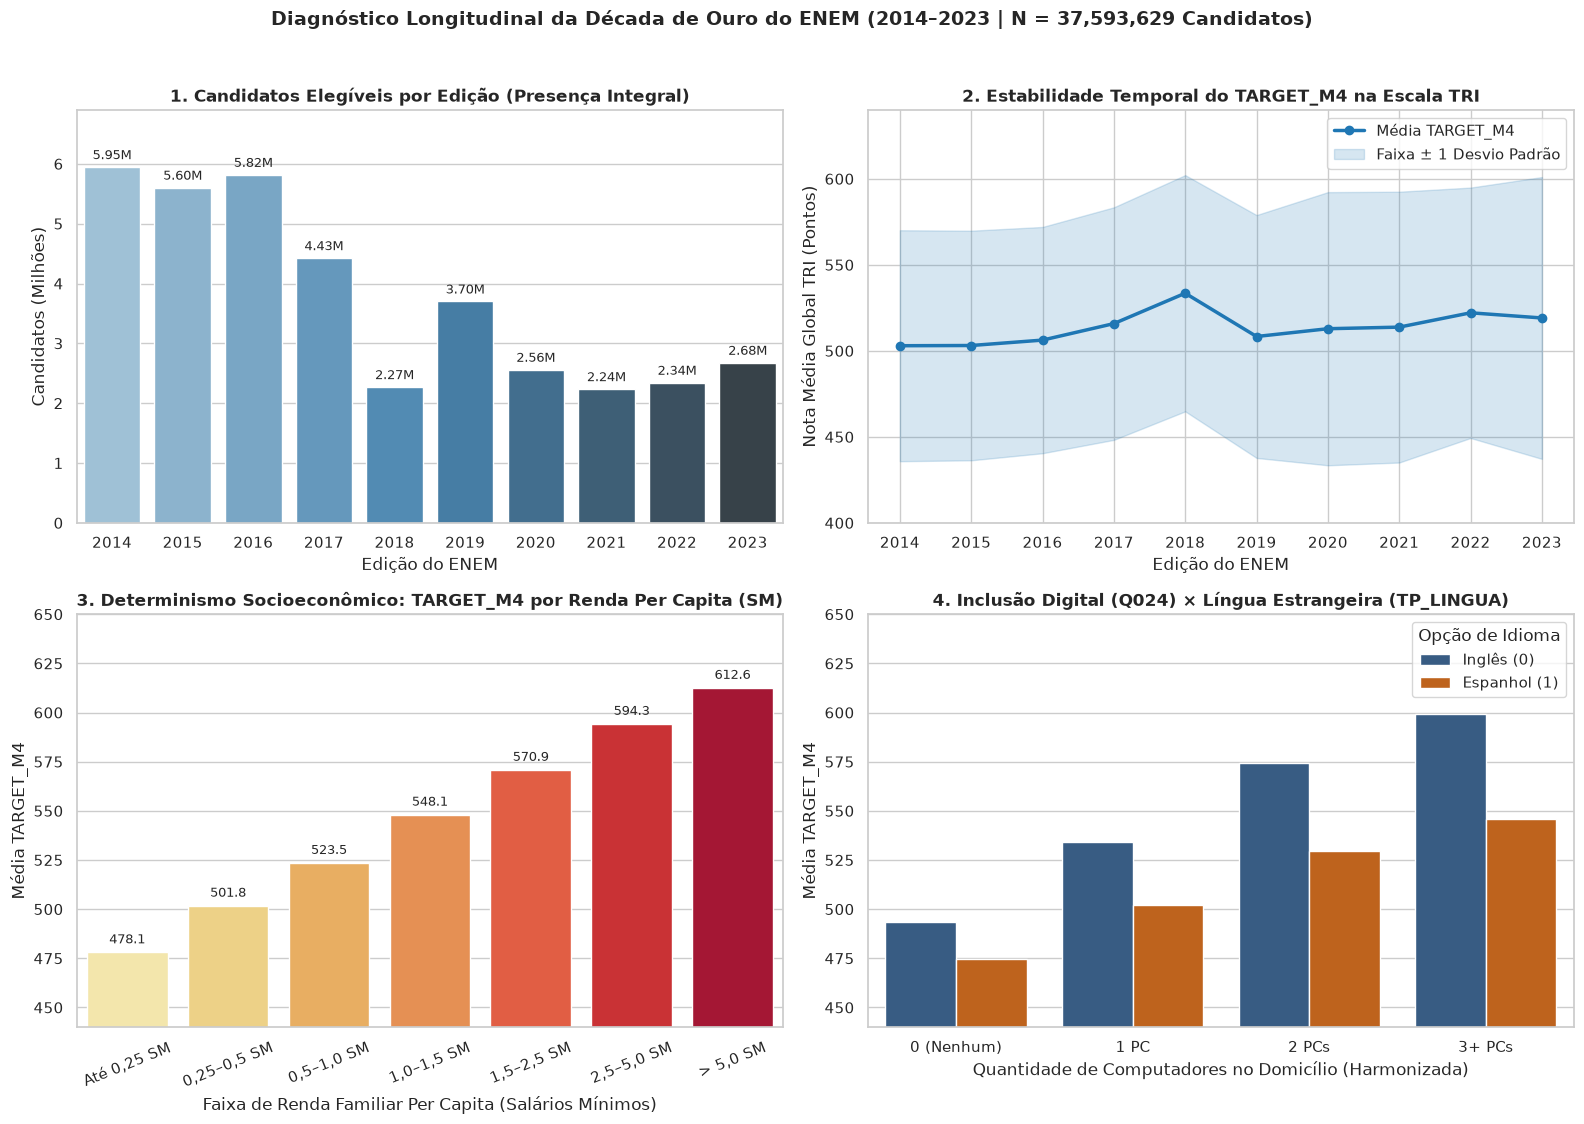

In [9]:
# ==============================================================================
# SEÇÃO 7: PAINEL VISUAL LONGITUDINAL DA DÉCADA DE OURO (2014–2023)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    f"Diagnóstico Longitudinal da Década de Ouro do ENEM (2014–2023 | N = {len(df_decada):,} Candidatos)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

# ── Bloco 7.1: Gráfico 1 — Volume anual de candidatos com presença integral ───
stats_ano = (
    df_decada.groupby("NU_ANO", observed=True)["TARGET_M4"]
    .agg(contagem="count", media="mean", dp="std")
    .reset_index()
)
anos_str = stats_ano["NU_ANO"].astype(str)
contagem_milhoes = stats_ano["contagem"] / 1e6

sns.barplot(
    x=anos_str,
    y=contagem_milhoes,
    hue=anos_str,
    palette="Blues_d",
    legend=False,
    ax=axes[0, 0],
)
axes[0, 0].set_title("1. Candidatos Elegíveis por Edição (Presença Integral)")
axes[0, 0].set_xlabel("Edição do ENEM")
axes[0, 0].set_ylabel("Candidatos (Milhões)")
for idx, val in enumerate(contagem_milhoes):
    axes[0, 0].text(idx, val + 0.08, f"{val:.2f}M", ha="center", va="bottom", fontsize=9)
axes[0, 0].set_ylim(0, contagem_milhoes.max() * 1.16)

# ── Bloco 7.2: Gráfico 2 — Estabilidade temporal do TARGET_M4 (Média ± 1 DP) ──
axes[0, 1].plot(
    anos_str,
    stats_ano["media"],
    marker="o",
    linewidth=2.5,
    color="#1f77b4",
    label="Média TARGET_M4",
)
axes[0, 1].fill_between(
    range(len(anos_str)),
    stats_ano["media"] - stats_ano["dp"],
    stats_ano["media"] + stats_ano["dp"],
    color="#1f77b4",
    alpha=0.18,
    label="Faixa ± 1 Desvio Padrão",
)
axes[0, 1].set_title("2. Estabilidade Temporal do TARGET_M4 na Escala TRI")
axes[0, 1].set_xlabel("Edição do ENEM")
axes[0, 1].set_ylabel("Nota Média Global TRI (Pontos)")
axes[0, 1].set_ylim(400, 640)
axes[0, 1].legend(loc="upper right")

# ── Bloco 7.3: Gráfico 3 — Gradiente de TARGET_M4 por Renda Per Capita (SM) ───
bins_sm = [-0.01, 0.25, 0.50, 1.00, 1.50, 2.50, 5.00, 30.0]
labels_sm = [
    "Até 0,25 SM",
    "0,25–0,5 SM",
    "0,5–1,0 SM",
    "1,0–1,5 SM",
    "1,5–2,5 SM",
    "2,5–5,0 SM",
    "> 5,0 SM",
]
faixa_sm = pd.cut(df_decada["RENDA_PER_CAPITA"], bins=bins_sm, labels=labels_sm)
media_por_renda = (
    df_decada.groupby(faixa_sm, observed=True)["TARGET_M4"]
    .mean()
    .reindex(labels_sm)
)

sns.barplot(
    x=media_por_renda.index.astype(str),
    y=media_por_renda.values,
    hue=media_por_renda.index.astype(str),
    palette="YlOrRd",
    legend=False,
    ax=axes[1, 0],
)
axes[1, 0].set_title("3. Determinismo Socioeconômico: TARGET_M4 por Renda Per Capita (SM)")
axes[1, 0].set_xlabel("Faixa de Renda Familiar Per Capita (Salários Mínimos)")
axes[1, 0].set_ylabel("Média TARGET_M4")
axes[1, 0].tick_params(axis="x", rotation=22)
axes[1, 0].set_ylim(440, 650)
for idx, val in enumerate(media_por_renda.values):
    axes[1, 0].text(idx, val + 3.0, f"{val:.1f}", ha="center", va="bottom", fontsize=9)

# ── Bloco 7.4: Gráfico 4 — Inclusão Digital (Q024) × Idioma (TP_LINGUA) ───────
rotulos_pc = {0: "0 (Nenhum)", 1: "1 PC", 2: "2 PCs", 3: "3+ PCs"}
rotulos_lingua = {0: "Inglês (0)", 1: "Espanhol (1)"}
interacao_df = (
    df_decada.groupby(["Q024", "TP_LINGUA"], observed=True)["TARGET_M4"]
    .mean()
    .reset_index()
)
interacao_df["Posse_PC"] = interacao_df["Q024"].map(rotulos_pc)
interacao_df["Idioma"] = interacao_df["TP_LINGUA"].map(rotulos_lingua)

sns.barplot(
    data=interacao_df,
    x="Posse_PC",
    y="TARGET_M4",
    hue="Idioma",
    palette=["#2b5c8f", "#d95f02"],
    ax=axes[1, 1],
)
axes[1, 1].set_title("4. Inclusão Digital (Q024) × Língua Estrangeira (TP_LINGUA)")
axes[1, 1].set_xlabel("Quantidade de Computadores no Domicílio (Harmonizada)")
axes[1, 1].set_ylabel("Média TARGET_M4")
axes[1, 1].set_ylim(440, 650)
axes[1, 1].legend(title="Opção de Idioma")

plt.tight_layout()
plt.show()

---
## 8. Exportação do Artefato Oficial Unificado e Contrato Criptográfico (SHA-256)

### O que esta última célula gera e por que ela é indispensável para MLOps?
Finalizamos o Notebook 05 em **3 blocos de governança**:
* **Bloco 8.1 (Gravação do Parquet Único Consolidado):** Salva `data/processed/enem_2014_2023_consolidado.parquet` comprimido com `snappy`, permitindo que o **Notebook 06 (`06_treinamento_modelo.ipynb`)** carregue toda a década em ~2 a 3 segundos.
* **Bloco 8.2 (Assinatura Criptográfica SHA-256 em *Streaming*):** Lê o arquivo Parquet em blocos de 8 MB para gerar seu hash único `SHA-256` (garantindo rastreabilidade de dados no MLflow sem gastar memória RAM extra).
* **Bloco 8.3 (Exportação do Manifesto `contrato_consolidacao_2014_2023.json`):** Congela os dicionários de harmonização, tipos físicos e estatísticas anuais para que o treinamento no **Notebook 06**, o serviço **FastAPI (`enem.pkl`)** na Etapa 2 e a DAG do **Airflow (`2024`)** na Etapa 3 compartilhem exatamente a mesma régua matemática.

In [10]:
# ==============================================================================
# SEÇÃO 8: PERSISTÊNCIA DO PARQUET UNIFICADO E MANIFESTO DE LINHAGEM (SHA-256)
# ==============================================================================
t0_export = time.perf_counter()

# ── Bloco 8.1: Exportação colunar comprimida (Apache Parquet + Snappy) ────────
df_decada.to_parquet(
    CAMINHO_PARQUET_FINAL,
    engine="pyarrow",
    compression="snappy",
    index=False,
)


# ── Bloco 8.2: Cálculo do hash SHA-256 em streaming (custo zero de RAM) ───────
def calcular_sha256_arquivo(caminho: Path, tamanho_bloco: int = 8 * 1024 * 1024) -> str:
    """Calcula a assinatura SHA-256 lendo o arquivo em blocos fixos de 8 MB."""
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        while bloco := f.read(tamanho_bloco):
            h.update(bloco)
    return h.hexdigest()


sha256_parquet = calcular_sha256_arquivo(CAMINHO_PARQUET_FINAL)
tamanho_parquet_final_mb = round(CAMINHO_PARQUET_FINAL.stat().st_size / (1024 ** 2), 2)
ram_dataframe_final_mb = round(df_decada.memory_usage(deep=True).sum() / (1024 ** 2), 2)

# ── Bloco 8.3: Montagem e gravação do contrato formal para Notebook 06 e API ──
contrato_consolidacao = {
    "nome_contrato": "enem_decada_ouro_2014_2023_consolidado",
    "versao_contrato": "1.0",
    "data_geracao_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "insumo_governanca_semantica": {
        "arquivo": str(CAMINHO_SCHEMA_MAPPING.relative_to(PROJECT_ROOT)),
        "versao_schema_mapping": metadata_sbert.get("versao_contrato", "3.5"),
    },
    "artefato_parquet": {
        "caminho_relativo": str(CAMINHO_PARQUET_FINAL.relative_to(PROJECT_ROOT)),
        "compressao": "snappy",
        "tamanho_disco_mb": tamanho_parquet_final_mb,
        "consumo_ram_dataframe_mb": ram_dataframe_final_mb,
        "bytes_por_registro_ram": int(sum(np.dtype(t).itemsize for t in TIPOS_COMPACTOS.values())),
        "sha256": sha256_parquet,
        "n_registros_totais": int(len(df_decada)),
        "n_colunas": int(df_decada.shape[1]),
        "anos_incluidos": ANOS_HOMOLOGADOS,
    },
    "definicao_papel_colunas": {
        "coluna_particao_temporal": {
            "nome": COLUNA_PARTICAO_TEMPORAL,
            "dtype": TIPOS_COMPACTOS[COLUNA_PARTICAO_TEMPORAL],
            "regra": (
                "Utilizar exclusivamente para split temporal/estratificação e auditoria de drift. "
                "NUNCA incluir em X."
            ),
        },
        "features_ordenadas": FEATURES_ELITE,
        "alvo_modelagem": {
            "nome": ALVO_OFICIAL,
            "dtype": TIPOS_COMPACTOS[ALVO_OFICIAL],
            "formula": "(NU_NOTA_CN + NU_NOTA_CH + NU_NOTA_LC + NU_NOTA_MT) / 4.0",
            "limites_validos": [0.0, 1000.0],
            "media_global_decada": round(float(df_decada[ALVO_OFICIAL].mean()), 4),
            "desvio_padrao_global_decada": round(float(df_decada[ALVO_OFICIAL].std()), 4),
        },
    },
    "regras_harmonizacao_e_inferencia": {
        "RENDA_PER_CAPITA": {
            "dtype": "float32",
            "unidade": "salarios_minimos_por_morador",
            "formula": "MAPA_Q006_SALARIOS_MINIMOS[Q006] / Q005",
            "mapa_q006_salarios_minimos": MAPA_Q006_SALARIOS_MINIMOS,
            "dominio_moradores_q005": [1, 20],
        },
        "Q024": {
            "dtype": "int8",
            "significado": {
                "0": "Nenhum computador",
                "1": "1 computador",
                "2": "2 computadores",
                "3": "3 ou mais computadores",
            },
            "mapa_2014_q010": MAPA_Q024_2014,
            "mapa_2015_2023_q024": MAPA_Q024_2015_2023,
        },
        "TP_ANO_CONCLUIU": {
            "dtype": "int8",
            "significado": (
                "Anos decorridos desde a conclusão do EM harmonizados no intervalo estacionário [0, 9], "
                "onde 0 = Não informado/Concluinte e 9 = 9 ou mais anos."
            ),
            "teto_harmonizado": TETO_ANOS_CONCLUSAO,
        },
        "TP_LINGUA": {
            "dtype": "int8",
            "significado": {"0": "Inglês", "1": "Espanhol"},
        },
        "TP_SEXO": {
            "dtype": "int8",
            "significado": {"0": "Feminino (F)", "1": "Masculino (M)"},
        },
        "Q002": {
            "dtype": "int8",
            "significado": {
                "0": "Nunca estudou",
                "1": "EF I incompleto",
                "2": "EF I completo / EF II incompleto",
                "3": "EF completo / EM incompleto",
                "4": "EM completo / Superior incompleto",
                "5": "Superior completo",
                "6": "Pós-graduação",
                "7": "Não sei",
            },
            "mapa_2014_q002": MAPA_Q002_2014,
            "mapa_2015_2023_q002": MAPA_Q002_2015_2023,
        },
    },
    "linhagem_censitaria_por_edicao": auditoria_anual,
}

with open(CAMINHO_CONTRATO_FINAL, "w", encoding="utf-8") as f_json:
    json.dump(contrato_consolidacao, f_json, indent=2, ensure_ascii=False)

print("=" * 95)
print("NOTEBOOK 05 CONCLUÍDO COM SUCESSO — ARTEFATOS DA DÉCADA DE OURO EXPORTADOS")
print("=" * 95)
print(f"• Parquet Consolidado : {CAMINHO_PARQUET_FINAL}")
print(f"• Tamanho em Disco    : {tamanho_parquet_final_mb:.2f} MB (compressão snappy)")
print(f"• Consumo em RAM      : {ram_dataframe_final_mb:.2f} MB ({len(df_decada):,} registros)")
print(f"• Hash SHA-256        : {sha256_parquet}")
print(f"• Manifesto JSON      : {CAMINHO_CONTRATO_FINAL}")
print(f"• Tempo de Exportação : {time.perf_counter() - t0_export:.2f} s")
print("-" * 95)
print("Próxima etapa após validação: 06_treinamento_modelo.ipynb (Random Forest vs. XGBoost + MLflow -> enem.pkl)")

NOTEBOOK 05 CONCLUÍDO COM SUCESSO — ARTEFATOS DA DÉCADA DE OURO EXPORTADOS
• Parquet Consolidado : /home/saulo/mba/tcc/enem/data/processed/enem_2014_2023_consolidado.parquet
• Tamanho em Disco    : 153.17 MB (compressão snappy)
• Consumo em RAM      : 537.78 MB (37,593,629 registros)
• Hash SHA-256        : a7fbce7cd5f6e89244351c8712be588f53dbbdf4ff46e9d3b397157647438d3a
• Manifesto JSON      : /home/saulo/mba/tcc/enem/data/processed/contrato_consolidacao_2014_2023.json
• Tempo de Exportação : 12.97 s
-----------------------------------------------------------------------------------------------
Próxima etapa após validação: 06_treinamento_modelo.ipynb (Random Forest vs. XGBoost + MLflow -> enem.pkl)
